# NABDH demo: the grid signs its own data

TSYP14 EnergyMind Tunisia, Phase 1 prototype.

This notebook walks through the whole prototype with its outputs saved, so you can read it
on GitHub without installing anything. Each step is short:

1. Load the simulated feeder (24 smart meters, 1 reading per second).
2. See the **pulse**: why genuine data and fake data look different.
3. Calibrate NABDH on clean data and run it on a test hour.
4. Read the verdicts, explanations and who-decides routing.
5. Check that the decision log is tamper-evident.
6. Full Phase 1 scores against a classic anomaly detector.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from nabdh import dataset, governance
from nabdh.detector import NabdhDetector
from nabdh.explain import explain
from nabdh.audit import AuditLog, verify

BLUE, ORANGE = "#2a78d6", "#eb6834"
pd.set_option("display.width", 140)

## 1. The data

Six one-hour episodes of one Tunisian low-voltage feeder. Two clean ones are for calibration
only, four test ones contain injected data problems, real equipment faults and real grid
events. Every injection is listed in `data/ground_truth.csv`.

In [2]:
episodes, gt, split = dataset.load(ROOT / "data")
E = {e.spec.name: e for e in episodes}
print("train:", split["train"]); print("test: ", split["test"])
gt.groupby("kind").size().rename("count").to_frame()

train: ['train_summer_evening', 'train_winter_morning']
test:  ['test_summer_evening', 'test_summer_heatwave', 'test_ramadan_iftar', 'test_winter_morning']


,count
kind,
BIAS,8
DRIFT,8
EQUIPMENT_FAULT,4
FABRICATED,8
GRID_EVENT,8
REPLAY,8
STUCK,8


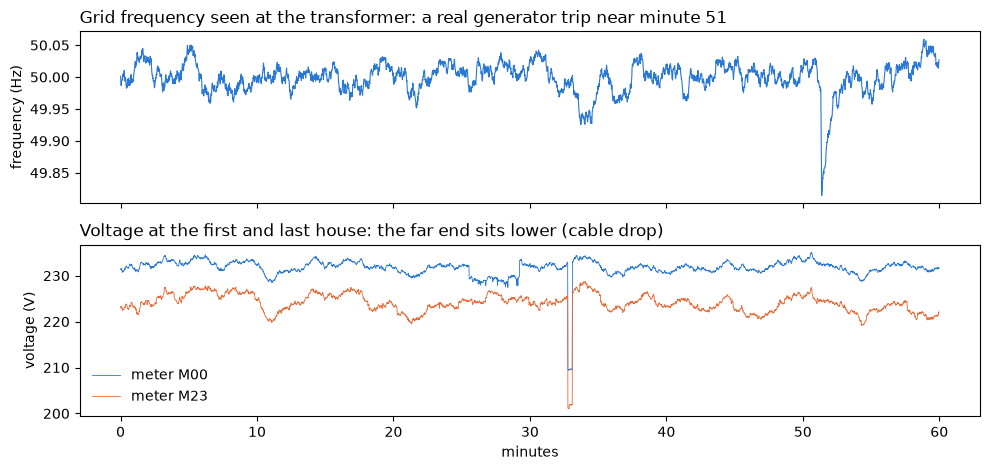

In [3]:
ep = E["test_summer_evening"]
t = ep.t / 60
fig, ax = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True)
ax[0].plot(t, ep.tx_f, color=BLUE, lw=0.8); ax[0].set_ylabel("frequency (Hz)")
ax[0].set_title("Grid frequency seen at the transformer: a real generator trip near minute 51", loc="left")
for j, c in [(0, BLUE), (23, ORANGE)]:
    ax[1].plot(t, ep.meter_v[:, j], lw=0.6, color=c, label=f"meter M{j:02d}")
ax[1].set_ylabel("voltage (V)"); ax[1].set_xlabel("minutes"); ax[1].legend(frameon=False)
ax[1].set_title("Voltage at the first and last house: the far end sits lower (cable drop)", loc="left")
plt.tight_layout(); plt.show()

## 2. The pulse

We never compare raw values. We compare second-by-second **changes** with the reference.
A genuine meter follows the grid's random wobble; data that was not measured here and now
does not. Below: one genuine meter, one fabricated stream, one replayed stream, all taken
from the test data.

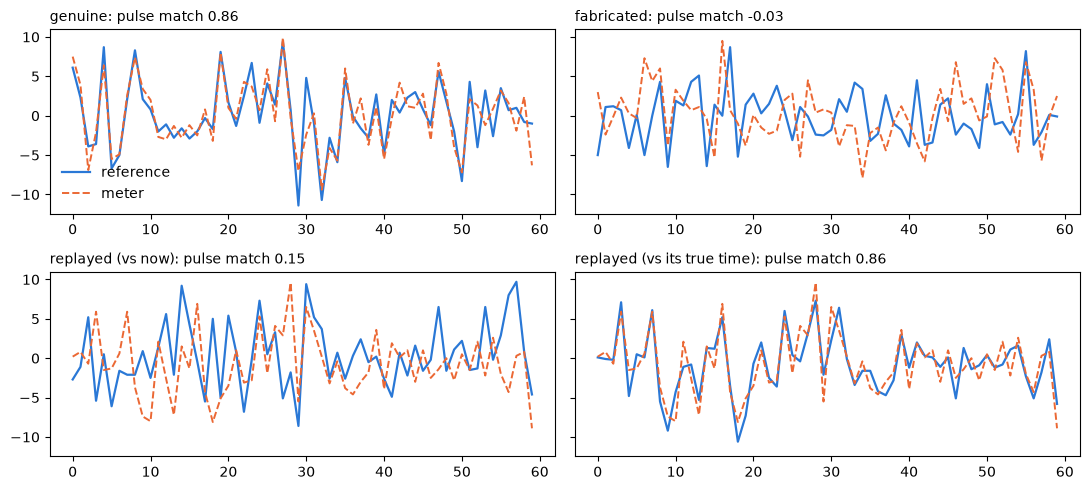

The replayed stream was injected with a lag of 699 s.


In [4]:
def pulse(ep, j, t0, ref_t0=None, n=60):
    ref_t0 = t0 if ref_t0 is None else ref_t0
    ref = np.diff(ep.tx_f[ref_t0:ref_t0 + n + 1]) * 1000
    m = np.diff(ep.meter_f[t0:t0 + n + 1, j]) * 1000
    return ref, m, np.corrcoef(ref, m)[0, 1]

fab = gt[gt.kind == "FABRICATED"].iloc[0]; rep = gt[gt.kind == "REPLAY"].iloc[0]
cases = [("genuine", E["test_summer_evening"], 10, 600, None),
         ("fabricated", E[fab.episode], int(fab.meter), int(fab.t0) + 60, None),
         ("replayed (vs now)", E[rep.episode], int(rep.meter), int(rep.t0) + 60, None),
         ("replayed (vs its true time)", E[rep.episode], int(rep.meter), int(rep.t0) + 60,
          int(rep.t0) + 60 - int(rep.param))]
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharey=True)
for ax, (name, e, j, t0, rt0) in zip(axes.ravel(), cases):
    ref, m, c = pulse(e, j, t0, rt0)
    ax.plot(ref, color=BLUE, lw=1.6, label="reference"); ax.plot(m, color=ORANGE, lw=1.4, ls="--", label="meter")
    ax.set_title(f"{name}: pulse match {c:.2f}", loc="left", fontsize=10)
axes[0, 0].legend(frameon=False); plt.tight_layout(); plt.show()
print(f"The replayed stream was injected with a lag of {int(rep.param)} s.")

## 3. Calibrate on clean data, run on a test hour

`fit` learns the thresholds from the two clean episodes only. The test episodes are never
used for tuning.

In [5]:
det = NabdhDetector().fit([E[n] for n in split["train"]])
print({k: round(v, 3) for k, v in vars(det.th).items() if k != "res_offset"})

ep = E["test_summer_evening"]
out = det.detect(ep)
T, N = ep.meter_v.shape
starts, lab = dataset.window_labels(ep.spec.name, T, N, gt, 60, 30)
idx = {s: k for k, s in enumerate(starts)}
out["label"] = [lab[idx[a], b] for a, b in zip(out.t0, out.meter)]
print(f"{len(out)} meter-windows checked, {out.attrs['ms_per_window']:.1f} ms per window for all 24 meters")

{'f_corr': 0.5, 'v_corr': 0.5, 'res_abs': 0.3, 'gap_abs': 0.15, 'if_score': 0.796}


2856 meter-windows checked, 8.8 ms per window for all 24 meters


In [6]:
scored = out[out.label.notna()]
pd.crosstab(scored.label, scored.verdict)

verdict,BIAS,DRIFT,EQUIPMENT_FAULT,FABRICATED,GRID_EVENT,NORMAL,REPLAY,STUCK
label,,,,,,,,
BIAS,20,0,0,0,0,1,0,0
DRIFT,0,15,0,2,0,0,0,0
EQUIPMENT_FAULT,0,7,6,0,0,1,0,0
FABRICATED,0,0,0,26,0,0,0,0
GRID_EVENT,0,0,0,0,136,0,0,0
NORMAL,0,0,0,0,0,2553,0,0
REPLAY,0,1,0,2,0,0,31,0
STUCK,0,0,0,0,0,0,0,34


## 4. Verdicts, explanations, routing

Consecutive windows become incidents. Each one gets a plain-language explanation and a
route: AUTO (the AI acts), ASSIST (one click) or HUMAN (the operator decides).

In [7]:
inc = governance.incidents(out[out.verdict != "NORMAL"], 30)
inc["route"] = [governance.route(v, c)[0] for v, c in zip(inc.verdict, inc.confidence)]
show = inc.sort_values("confidence", ascending=False).drop_duplicates("verdict")
for r in show.itertuples():
    w = out[(out.meter == r.meter) & (out.t0 >= r.start) & (out.t0 <= r.end - 60)]
    truth = w.label.dropna().mode()
    truth = truth.iloc[0] if len(truth) else "transition"
    print(f"[{r.verdict} | confidence {r.confidence:.2f} | route {r.route} | ground truth: {truth}]")
    print("  " + explain(r)); print()

[GRID_EVENT | confidence 0.99 | route AUTO | ground truth: GRID_EVENT]
  Meter M01, window 50:30-51:30: genuine grid event. The grid frequency moved 186 mHz away from 50 Hz, and this meter saw it in step with the reference (pulse match 0.99). The data is real: act on the event, not on the meter.

[DRIFT | confidence 0.99 | route AUTO | ground truth: EQUIPMENT_FAULT]
  Meter M00, window 25:00-26:00: calibration drift. The meter still carries the pulse (match 0.84), so it is real and in place, but it reads -1.64 V away from what Ohm's law and its neighbours predict, and that offset does not follow its own current. The sensor moved, not the grid.

[FABRICATED | confidence 0.99 | route HUMAN | ground truth: FABRICATED]
  Meter M01, window 34:00-35:00: readings not measured here. Values look plausible, but their wobble does not match the grid pulse (match -0.01) or the feeder pulse (match 0.08), and no earlier moment matches either (best 0.50). Someone or something is generating these numbe

The ground truth is printed next to each example on purpose: one of them is an equipment
fault that NABDH labelled DRIFT, which is the weak spot we report in the proposal.

## 5. A tamper-evident decision log

Each record stores the hash of the previous one. Changing one past verdict breaks the chain
and `verify` points at the edited record.

In [8]:
import tempfile, os
path = Path(tempfile.mkdtemp()) / "log.jsonl"
log = AuditLog(path)
for r in inc.head(5).itertuples():
    log.append(meter=int(r.meter), verdict=r.verdict, confidence=float(r.confidence))
print("intact log:", verify(path))
lines = path.read_text().splitlines()
lines[2] = lines[2].replace(lines[2].split('"verdict": "')[1].split('"')[0], "NORMAL", 1)
path.write_text("\n".join(lines) + "\n")
print("after someone edits record 2:", verify(path))

intact log: (True, -1)
after someone edits record 2: (False, 2)


## 6. Phase 1 scores (all four test hours)

Computed by `scripts/evaluate.py`. The baseline is an Isolation Forest on the raw values,
the usual first approach to this problem.

In [9]:
m = json.loads((ROOT / "results" / "metrics.json").read_text())
keys = ["precision", "recall", "f1", "false_positive_rate"]
table = pd.DataFrame({"NABDH": [m["nabdh"][k] for k in keys],
                      "Isolation Forest on values": [m["baseline_isolation_forest_values_only"][k] for k in keys]},
                     index=keys)
table.loc["real grid events flagged as bad data"] = [m["nabdh"]["event_vs_data"]["mistaken_for_data_problem"],
    m["baseline_isolation_forest_values_only"]["flagged_rate_per_class"]["GRID_EVENT"]]
table.round(4)

,NABDH,Isolation Forest on values
precision,0.9668,0.0844
recall,0.9038,0.0522
f1,0.9342,0.0645
false_positive_rate,0.0018,0.0323
real grid events flagged as bad data,0.0056,0.3520


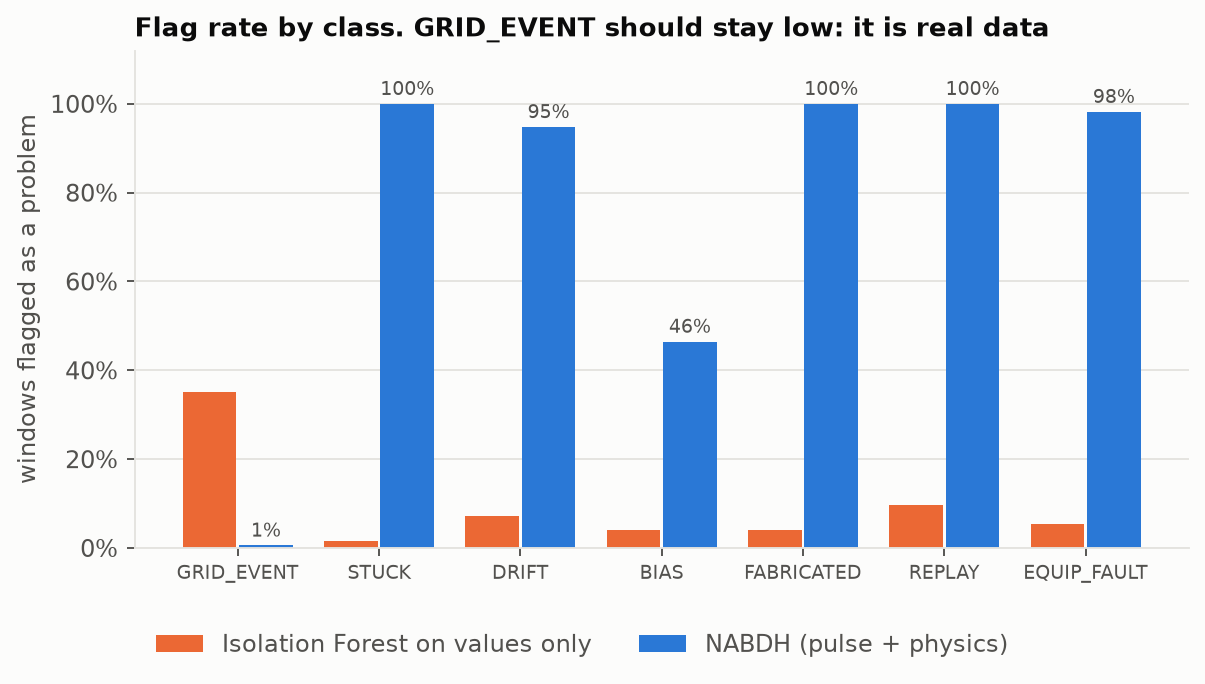

In [10]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "results" / "figures" / "fig3_baseline_comparison.png"), width=760))

## What this shows

- Fabricated and replayed data look normal by value, so a value-based detector misses them;
  the pulse catches them.
- Real grid events stay labelled as real events, so automated systems keep acting on them.
- Weak spots, measured: under-reporting meters are caught in about half the windows, and
  some equipment-fault windows are labelled DRIFT. Both are Phase 2 work.

Full design: `docs/NABDH_Proposal.pdf`.